# 05 · Customer Insights — corpus, contraste de vocabulário e QA5

**Tech Challenge Fase 4 · POSTECH DTAT · Grupo 12**

## Objetivo
Medir o texto das avaliações em duas frentes: o **contraste de vocabulário** entre as faixas de nota
(n-gramas e TF-IDF sobre **blocos de review**), que gera a tabela exibida na página 4 do dashboard, e a
**QA5** — *quais temas de reclamação predominam nos produtos de alto engajamento e baixa nota*.

As duas frentes recebem **métodos diferentes, e isso é decisão de escopo, não descuido**:

| Frente | Corpus | Método | Por quê |
|---|---|---|---|
| **Contraste de vocabulário** | 339 blocos (nota < 4,0) e 418 blocos (nota ≥ 4,3) | **TF-IDF + n-gramas** | há massa suficiente para que a frequência relativa signifique alguma coisa |
| **QA5** | **19 blocos** (alto engajamento + nota < 4,0) | **leitura qualitativa dirigida com protocolo de codificação — TF-IDF vedado** | 19 documentos não sustentam estatística de frequência: o IDF passa a descrever o acaso da amostra, não o tema |

A vedação está registrada em `method/definitions/escopo_perguntas.md`, seção 4. As duas decisões
coexistem e não se contradizem: o método acompanha o tamanho do corpus, não a preferência de quem analisa.

## Entradas

| Arquivo | Papel |
|---|---|
| `00_data/gold/base_analitica.csv` | base padrão, n = 1.348 — dá a nota, o engajamento e os rótulos de quadrante |
| `00_data/gold/reviews.csv` | 9.255 reviews distintos, deduplicados por `review_id` (T8) — **fonte oficial da contagem** |
| `00_data/silver/produtos_texto.csv` | **uso auxiliar e declarado**: é a única camada que carrega `review_content`; o gold não guarda texto |
| `src/paleta.py` | paleta v06 aplicada por ferramenta (T9) |

O **bronze é lido apenas para conferência** da contagem de referências. Nada é escrito nele.

## Saídas

| Arquivo | Conteúdo |
|---|---|
| `02_results/tables/tab14_ngramas.csv` | n-gramas por faixa de nota **e** o contraste entre nota < 4,0 e nota ≥ 4,3 |
| `02_results/tables/tab23_qa5_temas.csv` | os 9 eixos temáticos codificados nos 19 blocos de Q5 — insumo da página 4 do dashboard |
| `02_results/images/fig_nlp_01_truncamento_corpus.png` | referências por bloco — a limitação L1, medida |
| `02_results/images/fig_nlp_02_contraste_ngramas.png` | contraste TF-IDF entre as duas faixas extremas |
| `02_results/images/fig_nlp_03_qa5_eixos_tematicos.png` | eixos temáticos codificados nos 19 blocos de Q5 |

## As três contagens, ditas antes de qualquer número (T8)

Todo método textual deste projeto declara **unidade**, **deduplicação por `review_id`** e
**truncamento em 8**. As três contagens convivem e **não são intercambiáveis**:

| Termo | O que é | Contagem |
|---|---|---|
| **Bloco de review** | conjunto truncado de até 8 avaliações de um produto — **1 por produto** | **1.348** na base analítica |
| **Referência de avaliação** | item obtido ao explodir o bloco por `review_id` | **10.588** |
| **Review distinto** | referência após deduplicar por `review_id` | **9.255** (1.333 repetidas) |

## Limitações que este notebook carrega no corpo, não no rodapé

> **L1 — truncamento em 8 avaliações por produto (média medida: 7,85).**
> O texto analisado **não é amostra aleatória** do que os consumidores escreveram: é o recorte que o
> marketplace escolheu exibir na página do produto. **Consequência:** os achados descrevem
> **os temas visíveis na vitrine**, não a distribuição real das opiniões. Nenhuma conclusão deste
> notebook pode começar com *"a maioria dos clientes…"* — e nenhuma começa.

> **L2 — idioma do corpus.** As avaliações estão predominantemente em inglês, com ocorrências em
> outros idiomas e alfabetos não latinos. O pipeline **remove tokens não latinos**, o que descarta
> conteúdo real antes da análise. A parcela descartada é **medida** neste notebook, mas não é
> quantificada por idioma.

> **L7 — generalização.** O corpus descreve os produtos deste recorte de catálogo. Não há pesos amostrais.

## Regras transversais em vigor aqui
**T3** (fonte, base e *n* em todo número e toda figura) · **T4** (vedada linguagem causal) ·
**T6** (`rating_count` é volume de avaliações, nunca venda) · **T7** (nenhum identificador de
consumidor em saída alguma — por isso **este notebook não imprime texto bruto de avaliação**) ·
**T8** (unidade, deduplicação e truncamento declarados) · **T9** (paleta v06 por ferramenta).

## 1. Preparação

A primeira célula de código é sempre a mesma em todo notebook do projeto: carregar a paleta
**por ferramenta**. Escolher cor à mão é descumprimento de T9, mesmo que o resultado fique bonito.

In [1]:
import sys; sys.path.insert(0, "../src")
from paleta import confere_visual, aplicar, BASE, ESTRUTURA, CHAMADAS, CATEGORICA, checar_series
aplicar()  # T9 — paleta v06 aplicada por ferramenta, nunca no seletor

import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)


def achar_raiz(inicio=None):
    """Sobe a árvore até encontrar a raiz do repositório.

    O notebook precisa rodar tanto a partir de `01_notebooks/` (execução manual)
    quanto da raiz (execução por script). Fixar um caminho relativo quebraria um
    dos dois casos — e quebrar silenciosamente é pior do que não rodar.
    """
    atual = os.path.abspath(inicio or os.getcwd())
    for _ in range(6):
        if os.path.isdir(os.path.join(atual, "00_data")) and os.path.isdir(os.path.join(atual, "method")):
            return atual
        pai = os.path.dirname(atual)
        if pai == atual:
            break
        atual = pai
    raise FileNotFoundError("Raiz do repositório não encontrada a partir de " + os.getcwd())


RAIZ = achar_raiz()
GOLD = os.path.join(RAIZ, "00_data", "gold", "base_analitica.csv")
GOLD_REV = os.path.join(RAIZ, "00_data", "gold", "reviews.csv")
SILVER = os.path.join(RAIZ, "00_data", "silver", "produtos.csv")
# Texto livre em arquivo próprio (LGPD) — ver 00_data/README.md.
SILVER_TXT = os.path.join(RAIZ, "00_data", "silver", "produtos_texto.csv")
BRONZE = os.path.join(RAIZ, "00_data", "bronze", "amazon.csv")
IMG = os.path.join(RAIZ, "02_results", "images")
TAB = os.path.join(RAIZ, "02_results", "tables")
os.makedirs(IMG, exist_ok=True)
os.makedirs(TAB, exist_ok=True)

#: Acumula as conferências para a célula final de validação.
VALIDACAO = []


def conferir(rotulo, obtido, esperado):
    """Registra uma conferência contra o valor publicado no material."""
    ok = obtido == esperado
    VALIDACAO.append({"verificação": rotulo, "obtido": obtido, "esperado": esperado,
                      "situação": "confere" if ok else "DIVERGE"})
    return ok


def rodape(fig, fonte, base, n, extra="", tamanho=7.5):
    """Escreve o rodapé obrigatório de T3: fonte, base e n efetivo.

    Quebra em quantas linhas forem necessárias para caber na largura da figura.
    Rodapé cortado na borda é rodapé que não cumpre T3 — o avaliador não lê a
    metade que ficou fora do PNG.
    """
    import textwrap

    texto = f"Fonte: {fonte} · Base: {base} · n = {n}"
    if extra:
        texto += f" · {extra}"
    # Largura útil em caracteres: pontos disponíveis / largura média do glifo.
    orcamento = max(40, int((fig.get_figwidth() * 72 * 0.97) / (tamanho * 0.52)))
    linhas = textwrap.wrap(texto, width=orcamento)
    for i, linha in enumerate(reversed(linhas)):
        fig.text(0.01, 0.010 + i * (tamanho + 2.4) / (fig.get_figheight() * 72),
                 linha, fontsize=tamanho, color=ESTRUTURA["secundario"], ha="left")
    return len(linhas)


print("raiz do repositório :", os.path.basename(RAIZ) + "/")
print("paleta v06 aplicada :", plt.rcParams["axes.prop_cycle"].by_key()["color"][:3], "…")

raiz do repositório : Techchallenge4-G12/
paleta v06 aplicada : ['#F2C14E', '#3F5A7A', '#9AA5B1'] …


## 2. Por que a unidade é o **bloco**, e não o review individual

T8 exige declarar a unidade. Aqui a declaração não é formalidade: ela decorre de uma **limitação
verificável da origem**, e a verificação está abaixo.

Na origem, `review_id`, `review_title` e `review_content` são listas separadas por vírgula dentro
de uma única célula. O dicionário de dados manda "explodir junto". O problema é que **o texto das
avaliações contém vírgulas** — então separar o conteúdo por vírgula não devolve as avaliações:
devolve pedaços de frase.

A célula seguinte mede o alinhamento. Se a separação por vírgula fosse confiável, o número de
partes de `review_content` bateria com o número de `review_id` em ~100% dos produtos.

**Consequência metodológica:** `review_id` é deduplicável e contável — e é por isso que
`00_data/gold/reviews.csv` existe e vale como contagem oficial (9.255). O **texto**, esse, só é
recuperável como **bloco inteiro do produto**. Por isso o projeto declara, no registro, "unidade de
modelagem: o **bloco** de review, rotulado pela nota do produto". O notebook não contorna a
limitação — ele a mede e a respeita.

In [2]:
# Camadas. O texto só existe no silver; o gold traz os derivados e os rótulos de quadrante.
gold = pd.read_csv(GOLD)
reviews = pd.read_csv(GOLD_REV)
silver = pd.read_csv(SILVER)

texto = pd.read_csv(SILVER_TXT)[["product_id", "review_id",
                                 "review_title", "review_content"]]
base = gold.merge(texto, on="product_id", how="left", validate="1:1")

# Tratamento de exceção: sem texto não há análise de texto. Falhar aqui é melhor do que
# publicar um corpus silenciosamente menor do que o declarado.
faltando = int(base.review_content.isna().sum())
if faltando:
    raise ValueError(f"{faltando} blocos sem review_content — o corpus não fecha com o declarado")

# Alinhamento entre as três listas da origem.
n_ids = base.review_id.str.split(",").apply(len)
n_tit = base.review_title.fillna("").str.split(",").apply(len)
n_con = base.review_content.fillna("").str.split(",").apply(len)

print("Blocos carregados                      :", f"{len(base):,}".replace(",", "."))
print("Produtos sem texto                     :", faltando)
print()
print("Alinhamento das listas da origem (quanto maior, mais confiável seria explodir por vírgula)")
print(f"  review_title  bate com review_id     : {(n_tit == n_ids).mean() * 100:5.1f}%")
print(f"  review_content bate com review_id    : {(n_con == n_ids).mean() * 100:5.1f}%")
print()
print("Leitura: com ~13% de alinhamento, separar o CONTEÚDO por vírgula produziria fragmentos de")
print("frase, não avaliações. A unidade de texto é o BLOCO do produto (T8) — declarado, não suposto.")

Blocos carregados                      : 1.348
Produtos sem texto                     : 0

Alinhamento das listas da origem (quanto maior, mais confiável seria explodir por vírgula)
  review_title  bate com review_id     :  67.1%
  review_content bate com review_id    :  13.3%

Leitura: com ~13% de alinhamento, separar o CONTEÚDO por vírgula produziria fragmentos de
frase, não avaliações. A unidade de texto é o BLOCO do produto (T8) — declarado, não suposto.


## 3. As três contagens do corpus (T8) e o truncamento (L1)

Aqui o corpus é reconciliado contra `method/definitions/base_factual_e_bases_de_calculo.md` e
contra `method/definitions/registro_machine_learning.md`. Três números, lado a lado, por faixa de
nota — e o total de cada um.

A faixa intermediária (4,0 a 4,29) aparece porque **ela existe**: são 591 produtos, 44% do
portfólio, que ficam **fora** do contraste entre satisfação alta e baixa. O registro do projeto chama
isso de *lacuna declarada*. Omitir a linha seria fingir que o portfólio tem só dois extremos.

In [3]:
def faixa_de_nota(nota):
    """Faixas de nota — os mesmos cortes operacionais de satisfação (4,0 e 4,3)."""
    if nota < 4.0:
        return "< 4,0"
    if nota >= 4.3:
        return "≥ 4,3"
    return "4,0–4,29"


ORDEM_FAIXA = ["< 4,0", "4,0–4,29", "≥ 4,3"]
base["faixa_nota"] = base.nota.apply(faixa_de_nota)
base["refs_no_bloco"] = n_ids

# Referências: o bloco explodido por review_id. Reviews distintos: deduplicado (T8).
refs = base.assign(_rid=base.review_id.str.split(",")).explode("_rid")
refs["_rid"] = refs._rid.str.strip()
distintos = refs.drop_duplicates("_rid")

corpus = pd.DataFrame({
    "blocos": base.faixa_nota.value_counts(),
    "referencias": refs.faixa_nota.value_counts(),
    "reviews_distintos": distintos.faixa_nota.value_counts(),
}).reindex(ORDEM_FAIXA)
corpus.loc["TOTAL"] = corpus.sum()
corpus["repetidas"] = corpus.referencias - corpus.reviews_distintos

print("CORPUS — as três contagens, por faixa de nota (T8)")
print(corpus.to_string())
print()
print("Truncamento (L1): média de " + f"{base.refs_no_bloco.mean():.2f}".replace(".", ",")
      + f" referências por bloco · máximo {base.refs_no_bloco.max()} · mínimo {base.refs_no_bloco.min()}")
print(f"Blocos no teto de 8: {int((base.refs_no_bloco == 8).sum()):,}".replace(",", ".")
      + f" de {len(base):,}".replace(",", ".")
      + f" ({(base.refs_no_bloco == 8).mean() * 100:.1f}%)")
print()
print(f"Conferência contra 00_data/gold/reviews.csv: {len(reviews):,}".replace(",", ".")
      + " linhas — mesma contagem de reviews distintos?",
      len(reviews) == int(distintos._rid.nunique()))

conferir("blocos (base analítica)", len(base), 1348)
conferir("referências de avaliação", len(refs), 10588)
conferir("reviews distintos", int(distintos._rid.nunique()), 9255)
conferir("referências repetidas", len(refs) - int(distintos._rid.nunique()), 1333)
conferir("truncamento máximo", int(base.refs_no_bloco.max()), 8)
conferir("blocos nota < 4,0", int((base.faixa_nota == "< 4,0").sum()), 339)
conferir("blocos nota ≥ 4,3", int((base.faixa_nota == "≥ 4,3").sum()), 418)
conferir("reviews distintos nota < 4,0", int((distintos.faixa_nota == "< 4,0").sum()), 2502)
conferir("reviews distintos nota ≥ 4,3", int((distintos.faixa_nota == "≥ 4,3").sum()), 2878)
print("\nMédia de 7,85 confere?", round(float(base.refs_no_bloco.mean()), 2) == 7.85)

CORPUS — as três contagens, por faixa de nota (T8)
            blocos  referencias  reviews_distintos  repetidas
faixa_nota                                                   
< 4,0          339         2652               2502        150
4,0–4,29       591         4674               3875        799
≥ 4,3          418         3262               2878        384
TOTAL         1348        10588               9255       1333

Truncamento (L1): média de 7,85 referências por bloco · máximo 8 · mínimo 1
Blocos no teto de 8: 1.295 de 1.348 (96.1%)

Conferência contra 00_data/gold/reviews.csv: 9.255 linhas — mesma contagem de reviews distintos? True

Média de 7,85 confere? True


### 3.1 Conferência contra o bronze

O bronze é **somente leitura**. Ele entra aqui por um motivo só: mostrar que as 10.588 referências
não foram inventadas pela camada silver. A diferença entre o bronze e a base analítica é exatamente
a deduplicação de produtos e os dois cortes de qualidade — 1.465 → 1.351 → 1.348.

In [4]:
bronze = pd.read_csv(BRONZE, dtype=str)
refs_bronze = bronze.review_id.fillna("").str.split(",").apply(lambda p: len([x for x in p if x.strip()]))

print("BRONZE — origem intocada")
print(f"  linhas                    : {len(bronze):,}".replace(",", "."))
print(f"  referências de avaliação  : {refs_bronze.sum():,}".replace(",", "."))
print()
print("BASE ANALÍTICA — após deduplicação e cortes de qualidade")
print(f"  blocos                    : {len(base):,}".replace(",", "."))
print(f"  referências de avaliação  : {len(refs):,}".replace(",", "."))
print(f"  reviews distintos         : {distintos._rid.nunique():,}".replace(",", "."))
print()
print("Reconciliação das bases: 1.465 → 1.351 → 1.350 → 1.349 → 1.348")
print("  1.465 (bruta) − 114 linhas excedentes = 1.351 (produtos)")
print("  1.351 − 1 rating inválido = 1.350 · − 2 rating_count nulos = 1.348 (analítica)")
conferir("bronze — linhas", len(bronze), 1465)
conferir("silver — produtos", len(silver), 1351)

BRONZE — origem intocada
  linhas                    : 1.465
  referências de avaliação  : 11.503

BASE ANALÍTICA — após deduplicação e cortes de qualidade
  blocos                    : 1.348
  referências de avaliação  : 10.588
  reviews distintos         : 9.255

Reconciliação das bases: 1.465 → 1.351 → 1.350 → 1.349 → 1.348
  1.465 (bruta) − 114 linhas excedentes = 1.351 (produtos)
  1.351 − 1 rating inválido = 1.350 · − 2 rating_count nulos = 1.348 (analítica)


True

### 3.2 Figura 1 — o truncamento, medido

A limitação L1 costuma ser lida como ressalva de rodapé. Ela não é: **1.295 dos 1.348 blocos estão
no teto de 8 referências**. Isso não descreve um corpus com variação natural de tamanho — descreve
um corpus **cortado no mesmo ponto**, produto a produto. Um produto com 426.973 avaliações e um com
2 avaliações entregam **o mesmo tamanho de texto**.

É por isso que nenhuma frase deste notebook estima proporção de opinião.

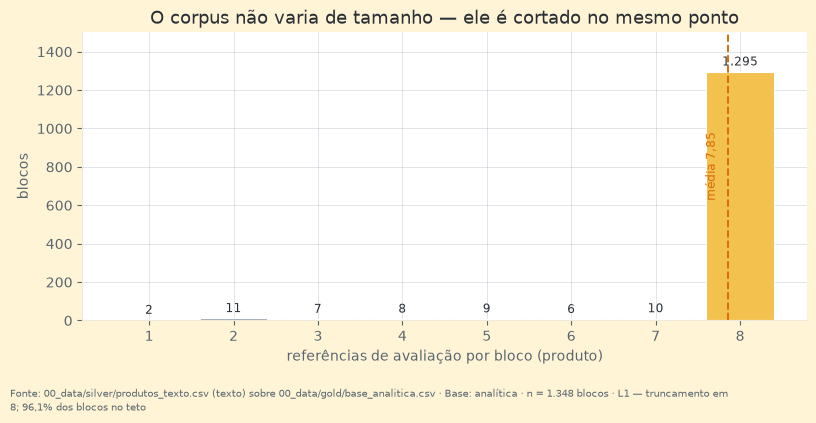

gravado: 02_results/images/fig_nlp_01_truncamento_corpus.png


In [5]:
dist = base.refs_no_bloco.value_counts().reindex(range(1, 9), fill_value=0)

fig, ax = plt.subplots(figsize=(8.2, 4.2))
cores = [ESTRUTURA["grade"]] * 7 + [CHAMADAS["destaque"]]
barras = ax.bar(dist.index, dist.values, color=cores, edgecolor=BASE["card"], linewidth=0.8)
for x, v in zip(dist.index, dist.values):
    if v:
        ax.text(x, v + 18, f"{v:,}".replace(",", "."), ha="center", va="bottom",
                fontsize=8.5, color=ESTRUTURA["tinta"])
ax.axvline(base.refs_no_bloco.mean(), color=CHAMADAS["atencao"], linestyle="--", linewidth=1.4)
ax.text(base.refs_no_bloco.mean() - 0.12, dist.max() * 0.62,
        "média " + f"{base.refs_no_bloco.mean():.2f}".replace(".", ","),
        rotation=90, ha="right", va="center", fontsize=8.5, color=CHAMADAS["atencao"])
ax.set_title("O corpus não varia de tamanho — ele é cortado no mesmo ponto")
ax.set_xlabel("referências de avaliação por bloco (produto)")
ax.set_ylabel("blocos")
ax.set_xticks(range(1, 9))
ax.set_ylim(0, dist.max() * 1.16)
rodape(fig, "00_data/silver/produtos_texto.csv (texto) sobre 00_data/gold/base_analitica.csv",
       "analítica", f"{len(base):,}".replace(",", ".") + " blocos",
       "L1 — truncamento em 8; 96,1% dos blocos no teto")
fig.tight_layout(rect=[0, 0.085, 1, 1])
destino = os.path.join(IMG, "fig_nlp_01_truncamento_corpus.png")
confere_visual(fig, "figura")          # T3 e T9 conferidos na figura
fig.savefig(destino, dpi=160)
plt.show()
print("gravado:", os.path.relpath(destino, RAIZ))

## 4. O pipeline declarado

`method/definitions/registro_machine_learning.md` fixa a ordem:

> **remoção de URLs → remoção de tokens não latinos → stopwords em inglês → n-gramas**

Cada passo tem um porquê, e cada passo **descarta conteúdo** — por isso cada um é contado.

1. **URLs.** A origem traz links de imagem colados no meio do texto
   (`https://m.media-amazon.com/images/…`). Um link vira dezenas de tokens sem significado
   semântico, e alguns se repetem entre produtos — o que inflaria o TF-IDF de forma artificial.
2. **Tokens não latinos.** Há avaliações em alfabetos não latinos. Esta é a **limitação L2** e é
   a mais desconfortável do bloco: o passo **descarta conteúdo real**, não ruído. A contagem abaixo
   dimensiona o que se perdeu. Não há quantificação por idioma — e isso se declara, não se disfarça.
   Observação honesta: texto em outro **idioma** escrito em **alfabeto latino** (há avaliações em
   híndi romanizado) **atravessa** este filtro e entra na análise como se fosse inglês.
3. **Stopwords em inglês.** Lista do NLTK (198 termos na versão 3.9.1). Sem isso, os n-gramas mais
   frequentes seriam `the`, `and`, `is` — verdadeiros e inúteis.
4. **Tokens com menos de 3 caracteres.** Passo adicional, **não previsto no registro** e por isso
   declarado aqui: remove restos de pontuação e siglas de uma letra. Está contado em separado para
   que a diferença contra o pipeline do registro seja auditável.

A dependência do NLTK é real: se o corpus de stopwords não estiver baixado, a célula **avisa e usa
a lista do scikit-learn**, dizendo qual usou. Um notebook que quebra na máquina do avaliador não
prova nada; um que troca a lista em silêncio, menos ainda.

In [6]:
def carregar_stopwords():
    """Devolve (conjunto de stopwords, origem declarada).

    Tenta o NLTK, que é o que o pipeline declara. Se o corpus não estiver
    baixado — caso comum em máquina nova ou sem rede — cai para a lista do
    scikit-learn e DIZ que caiu. Trocar a lista em silêncio mudaria os números
    sem deixar rastro.
    """
    try:
        import nltk
        from nltk.corpus import stopwords as nltk_sw
        try:
            palavras = nltk_sw.words("english")
        except LookupError:
            nltk.download("stopwords", quiet=True)
            palavras = nltk_sw.words("english")
        return set(palavras), f"NLTK {nltk.__version__} · corpus 'stopwords' (english)"
    except Exception as erro:
        from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
        print(f"AVISO: NLTK indisponível ({type(erro).__name__}). "
              "Usando a lista do scikit-learn — os números mudam levemente.")
        return set(ENGLISH_STOP_WORDS), "scikit-learn ENGLISH_STOP_WORDS (fallback declarado)"


STOPWORDS, ORIGEM_SW = carregar_stopwords()
print(f"Stopwords: {len(STOPWORDS)} termos · origem: {ORIGEM_SW}")

#: URL colada no texto — protocolo explícito ou `www.`.
RE_URL = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
#: Separadores. Mantém apóstrofo para não quebrar "doesn't" antes da stopword agir.
RE_SEP = re.compile(r"[\s,.;:!?()\[\]{}\"/\\|<>*#~_+=%$@^&`\-–—…]+")
#: Token latino: apenas letras do alfabeto latino (com acentuação) e apóstrofo.
RE_LATINO = re.compile(r"[a-zà-öø-ÿ']+")

#: Contador por etapa — o pipeline declara o que descarta.
ETAPAS = {"urls_removidas": 0, "tokens_iniciais": 0, "nao_latinos": 0,
          "stopwords": 0, "curtos": 0, "tokens_finais": 0}


def limpar_bloco(texto):
    """Aplica o pipeline declarado a um bloco de review e devolve o texto normalizado."""
    texto = str(texto)
    ETAPAS["urls_removidas"] += len(RE_URL.findall(texto))       # 1 — URLs
    texto = RE_URL.sub(" ", texto).lower()
    tokens = [t for t in RE_SEP.split(texto) if t]
    ETAPAS["tokens_iniciais"] += len(tokens)
    saida = []
    for token in tokens:
        if not RE_LATINO.fullmatch(token):                        # 2 — não latinos (L2)
            ETAPAS["nao_latinos"] += 1
            continue
        if token in STOPWORDS:                                    # 3 — stopwords em inglês
            ETAPAS["stopwords"] += 1
            continue
        if len(token) < 3:                                        # 4 — resíduo curto (declarado)
            ETAPAS["curtos"] += 1
            continue
        saida.append(token)
    ETAPAS["tokens_finais"] += len(saida)
    return " ".join(saida)


base["texto_limpo"] = base.review_content.fillna("").apply(limpar_bloco)

etapas = pd.DataFrame([
    {"etapa": "1 · URLs removidas (ocorrências)", "quantidade": ETAPAS["urls_removidas"], "% dos tokens iniciais": None},
    {"etapa": "— tokens iniciais", "quantidade": ETAPAS["tokens_iniciais"], "% dos tokens iniciais": 100.0},
    {"etapa": "2 · tokens não latinos descartados (L2)", "quantidade": ETAPAS["nao_latinos"],
     "% dos tokens iniciais": round(ETAPAS["nao_latinos"] / ETAPAS["tokens_iniciais"] * 100, 2)},
    {"etapa": "3 · stopwords em inglês descartadas", "quantidade": ETAPAS["stopwords"],
     "% dos tokens iniciais": round(ETAPAS["stopwords"] / ETAPAS["tokens_iniciais"] * 100, 2)},
    {"etapa": "4 · tokens com menos de 3 caracteres", "quantidade": ETAPAS["curtos"],
     "% dos tokens iniciais": round(ETAPAS["curtos"] / ETAPAS["tokens_iniciais"] * 100, 2)},
    {"etapa": "= tokens que chegam aos n-gramas", "quantidade": ETAPAS["tokens_finais"],
     "% dos tokens iniciais": round(ETAPAS["tokens_finais"] / ETAPAS["tokens_iniciais"] * 100, 2)},
])
print("\nPIPELINE — o que entra, o que sai (base analítica, 1.348 blocos)")
print(etapas.to_string(index=False))
print()
print(f"Blocos com ao menos uma URL: {int(base.review_content.apply(lambda t: bool(RE_URL.search(str(t)))).sum())}")
print("Leitura de L2: o descarte por alfabeto é pequeno em volume, e ainda assim é conteúdo real.")
print("Nenhum bloco ficou vazio após a limpeza?", bool((base.texto_limpo.str.len() > 0).all()))

Stopwords: 198 termos · origem: NLTK 3.9.1 · corpus 'stopwords' (english)

PIPELINE — o que entra, o que sai (base analítica, 1.348 blocos)
                                  etapa  quantidade  % dos tokens iniciais
       1 · URLs removidas (ocorrências)         228                    NaN
                      — tokens iniciais      341571                 100.00
2 · tokens não latinos descartados (L2)       12992                   3.80
    3 · stopwords em inglês descartadas      147369                  43.14
   4 · tokens com menos de 3 caracteres        4578                   1.34
       = tokens que chegam aos n-gramas      176632                  51.71

Blocos com ao menos uma URL: 216
Leitura de L2: o descarte por alfabeto é pequeno em volume, e ainda assim é conteúdo real.
Nenhum bloco ficou vazio após a limpeza? True


## 5. n-gramas mais frequentes por faixa de nota

**Unidade: o bloco.** A métrica é **frequência documental** — em quantos blocos o n-grama aparece
ao menos uma vez — e não contagem bruta de ocorrências. O motivo é direto: um bloco reúne até 8
avaliações, então um produto tagarela pesaria como oito produtos se a contagem fosse bruta.
Frequência documental faz cada **produto** valer um.

`min_df = 5` corta n-gramas que aparecem em menos de 5 blocos: abaixo disso o termo descreve um
produto específico, não um padrão.

**O que esta tabela mostra — e o que ela não mostra.** Os topos das três faixas são quase idênticos:
`good`, `product`, `quality`, `price`. Isso **não** é um achado sobre satisfação; é o vocabulário
comum de avaliação de e-commerce, e ele satura em qualquer faixa. O padrão útil só aparece no
**contraste** da seção 6. Publicar apenas esta tabela seria publicar a saturação como se fosse
descoberta.

In [7]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

GRAMAS = (1, 3)   # unigramas, bigramas e trigramas
MIN_DF = 5        # o n-grama precisa estar em pelo menos 5 blocos
TOPO = 15


def ngramas_por_faixa(df, faixa, topo=TOPO):
    """Frequência documental dos n-gramas de uma faixa. Unidade = bloco."""
    sub = df[df.faixa_nota == faixa]
    vetor = CountVectorizer(ngram_range=GRAMAS, min_df=MIN_DF, binary=True)
    matriz = vetor.fit_transform(sub.texto_limpo)
    termos = np.array(vetor.get_feature_names_out())
    freq = np.asarray(matriz.sum(axis=0)).ravel()
    ordem = np.argsort(-freq)[:topo]
    return pd.DataFrame({
        "faixa_nota": faixa,
        "n_blocos_faixa": len(sub),
        "grau": [len(termos[i].split()) for i in ordem],
        "n_grama": termos[ordem],
        "blocos_com_o_termo": freq[ordem],
        "share_blocos_pct": (freq[ordem] / len(sub) * 100).round(1),
    })


frequencia = pd.concat([ngramas_por_faixa(base, f) for f in ORDEM_FAIXA], ignore_index=True)

for f in ORDEM_FAIXA:
    bloco = frequencia[frequencia.faixa_nota == f]
    print(f"\nFAIXA {f} · {bloco.n_blocos_faixa.iloc[0]} blocos · top {TOPO} por frequência documental")
    print(bloco[["n_grama", "grau", "blocos_com_o_termo", "share_blocos_pct"]].to_string(index=False))

comuns = set(frequencia[frequencia.faixa_nota == "< 4,0"].n_grama) & set(frequencia[frequencia.faixa_nota == "≥ 4,3"].n_grama)
print(f"\nTermos presentes no topo das DUAS faixas extremas: {len(comuns)} de {TOPO} — {sorted(comuns)}")
print("É esta sobreposição que torna o contraste obrigatório.")


FAIXA < 4,0 · 339 blocos · top 15 por frequência documental
     n_grama  grau  blocos_com_o_termo  share_blocos_pct
        good     1                 314              92.6
     product     1                 300              88.5
     quality     1                 201              59.3
         use     1                 177              52.2
       price     1                 170              50.1
        nice     1                 158              46.6
         one     1                 150              44.2
        like     1                 143              42.2
     working     1                 140              41.3
good product     2                 135              39.8
       money     1                 132              38.9
        also     1                 127              37.5
        well     1                 117              34.5
       works     1                 108              31.9
         buy     1                 107              31.6

FAIXA 4,0–4,29 · 591 bloco

## 6. O contraste entre nota < 4,0 e nota ≥ 4,3

Aqui o TF-IDF é **válido**: 339 + 418 = 757 blocos. O corpus do ajuste são as duas faixas extremas,
e a medida publicada é a **diferença da média do peso TF-IDF** entre elas, termo a termo.

- `sublinear_tf=True` — amortece o peso de repetição dentro do bloco. Sem isso, um bloco que repete
  `battery` oito vezes domina a faixa inteira.
- `min_df=10` — o termo precisa aparecer em pelo menos 10 dos 757 blocos.
- A faixa intermediária **fica de fora**, por decisão de método registrada no projeto: 591 produtos,
  44% do portfólio. É a **lacuna declarada** e está dita aqui, não escondida.

**T4 em vigor:** o que segue são **associações** entre vocabulário e faixa de nota. Nenhum termo
"causa" nota baixa, e nenhuma frase abaixo diz isso.

### A ressalva que decide a leitura

O contraste mistura **tema** com **mix de produto**. As duas faixas não têm a mesma composição de
categoria — e termos como `remote`, `bass`, `cable` ou `mouse` são vocabulário de *categoria*, não
de satisfação. A célula seguinte mede a composição e, logo depois, refaz o contraste **dentro de
Electronics** — onde as duas faixas têm 128 e 136 blocos, ambas acima do piso de T2. Se um termo
sobrevive aos dois recortes, ele é candidato a padrão; se some, era mix.

In [8]:
mix = pd.crosstab(base.faixa_nota, base.categoria_n1, normalize="index").mul(100).round(1)
mix = mix.reindex(ORDEM_FAIXA)
principais = ["Electronics", "Home&Kitchen", "Computers&Accessories", "OfficeProducts"]
print("COMPOSIÇÃO DE CATEGORIA POR FAIXA (% dos blocos da faixa) — as 4 acima do piso de T2")
print(mix[principais].to_string())
print()
print("Leitura: a faixa < 4,0 tem 42,5% de Home&Kitchen contra 25,4% na faixa ≥ 4,3; a faixa ≥ 4,3")
print("tem 36,6% de Computers&Accessories contra 19,2%. O contraste de vocabulário carrega essa")
print("diferença de sortimento junto — por isso vem o recorte de controle.")

COMPOSIÇÃO DE CATEGORIA POR FAIXA (% dos blocos da faixa) — as 4 acima do piso de T2
categoria_n1  Electronics  Home&Kitchen  Computers&Accessories  OfficeProducts
faixa_nota                                                                    
< 4,0                37.8          42.5                   19.2             0.0
4,0–4,29             38.2          33.3                   26.2             1.7
≥ 4,3                32.5          25.4                   36.6             5.0

Leitura: a faixa < 4,0 tem 42,5% de Home&Kitchen contra 25,4% na faixa ≥ 4,3; a faixa ≥ 4,3
tem 36,6% de Computers&Accessories contra 19,2%. O contraste de vocabulário carrega essa
diferença de sortimento junto — por isso vem o recorte de controle.


In [9]:
def contraste_tfidf(df, rotulo_recorte, min_df=10, topo=15):
    """Diferença da média TF-IDF entre nota < 4,0 e nota ≥ 4,3. Unidade = bloco."""
    sub = df[df.faixa_nota.isin(["< 4,0", "≥ 4,3"])]
    vetor = TfidfVectorizer(ngram_range=GRAMAS, min_df=min_df, sublinear_tf=True)
    X = vetor.fit_transform(sub.texto_limpo)
    termos = np.array(vetor.get_feature_names_out())

    baixa = (sub.faixa_nota == "< 4,0").values
    media_baixa = np.asarray(X[baixa].mean(axis=0)).ravel()
    media_alta = np.asarray(X[~baixa].mean(axis=0)).ravel()
    delta = media_baixa - media_alta

    # Frequência documental no mesmo vocabulário, para publicar magnitude legível.
    binario = CountVectorizer(vocabulary=vetor.vocabulary_, ngram_range=GRAMAS, binary=True)
    B = binario.transform(sub.texto_limpo)
    share_baixa = np.asarray(B[baixa].sum(axis=0)).ravel() / baixa.sum() * 100
    share_alta = np.asarray(B[~baixa].sum(axis=0)).ravel() / (~baixa).sum() * 100

    linhas = []
    for lado, indices in [("< 4,0", np.argsort(-delta)[:topo]), ("≥ 4,3", np.argsort(delta)[:topo])]:
        for i in indices:
            linhas.append({
                "recorte": rotulo_recorte,
                "faixa_nota": lado,
                "grau": len(termos[i].split()),
                "n_grama": termos[i],
                "share_blocos_baixa_pct": round(float(share_baixa[i]), 1),
                "share_blocos_alta_pct": round(float(share_alta[i]), 1),
                "tfidf_medio_baixa": round(float(media_baixa[i]), 5),
                "tfidf_medio_alta": round(float(media_alta[i]), 5),
                "delta_tfidf": round(float(delta[i]), 5),
            })
    info = {"blocos": int(len(sub)), "baixa": int(baixa.sum()), "alta": int((~baixa).sum()),
            "vocabulario": int(len(termos))}
    return pd.DataFrame(linhas), info


contraste, info_geral = contraste_tfidf(base, "base analítica")
print(f"Corpus do contraste: {info_geral['blocos']} blocos "
      f"({info_geral['baixa']} com nota < 4,0 · {info_geral['alta']} com nota ≥ 4,3) · "
      f"vocabulário de {info_geral['vocabulario']} n-gramas (min_df = 10)")

for lado in ["< 4,0", "≥ 4,3"]:
    print(f"\nMais característico de nota {lado}")
    print(contraste[contraste.faixa_nota == lado][
        ["n_grama", "grau", "share_blocos_baixa_pct", "share_blocos_alta_pct", "delta_tfidf"]
    ].to_string(index=False))

conferir("blocos no contraste (339 + 418)", info_geral["blocos"], 757)

Corpus do contraste: 757 blocos (339 com nota < 4,0 · 418 com nota ≥ 4,3) · vocabulário de 1663 n-gramas (min_df = 10)

Mais característico de nota < 4,0
      n_grama  grau  share_blocos_baixa_pct  share_blocos_alta_pct  delta_tfidf
       remote     1                    11.8                    8.4      0.01619
         bass     1                    10.3                    1.7      0.01300
        noise     1                    13.9                    4.3      0.01256
      average     1                    15.3                    6.7      0.01010
sound quality     2                    13.9                    6.5      0.00958
          bad     1                    18.0                    9.1      0.00953
      working     1                    41.3                   36.6      0.00951
         item     1                    10.9                    5.0      0.00912
      battery     1                    23.0                   14.1      0.00875
      heating     1                    10.3   

True

In [10]:
# Recorte de controle: mesma medida, só Electronics — a categoria mais equilibrada entre as faixas.
electronics = base[base.categoria_n1 == "Electronics"]
contraste_el, info_el = contraste_tfidf(electronics, "Electronics")
print(f"Controle Electronics: {info_el['blocos']} blocos "
      f"({info_el['baixa']} com nota < 4,0 · {info_el['alta']} com nota ≥ 4,3) — "
      "as duas faixas acima do piso de 30 (T2)")

for lado in ["< 4,0", "≥ 4,3"]:
    geral = set(contraste[contraste.faixa_nota == lado].n_grama)
    ctrl = set(contraste_el[contraste_el.faixa_nota == lado].n_grama)
    print(f"\n  nota {lado} — sobrevivem aos dois recortes: {sorted(geral & ctrl)}")
    print(f"  nota {lado} — só no recorte geral (candidatos a mix de sortimento): {sorted(geral - ctrl)}")

Controle Electronics: 264 blocos (128 com nota < 4,0 · 136 com nota ≥ 4,3) — as duas faixas acima do piso de 30 (T2)

  nota < 4,0 — sobrevivem aos dois recortes: ['average', 'bass', 'buttons', 'ear', 'noise', 'properly', 'remote', 'sound quality', 'working']
  nota < 4,0 — só no recorte geral (candidatos a mix de sortimento): ['bad', 'battery', 'cord', 'heating', 'item', 'poor']

  nota ≥ 4,3 — sobrevivem aos dois recortes: ['cable', 'easy', 'excellent', 'fast', 'got', 'screen', 'speed']
  nota ≥ 4,3 — só no recorte geral (candidatos a mix de sortimento): ['best', 'cables', 'great', 'laptop', 'looks', 'mouse', 'smooth', 'using']


### 6.1 Figura 2 — o contraste, lido de uma vez

Barras divergentes: à esquerda, os n-gramas com maior peso relativo nos blocos de **nota < 4,0**;
à direita, os de **nota ≥ 4,3**. O eixo é a **diferença da média TF-IDF** — magnitude, não ranking
puro (T5). Duas séries, dentro do limite de T9.

O rótulo ao lado de cada barra traz a **frequência documental nas duas faixas**, porque a diferença
de TF-IDF sozinha não diz quão comum o termo é. Magnitude sem base é número solto (T3).

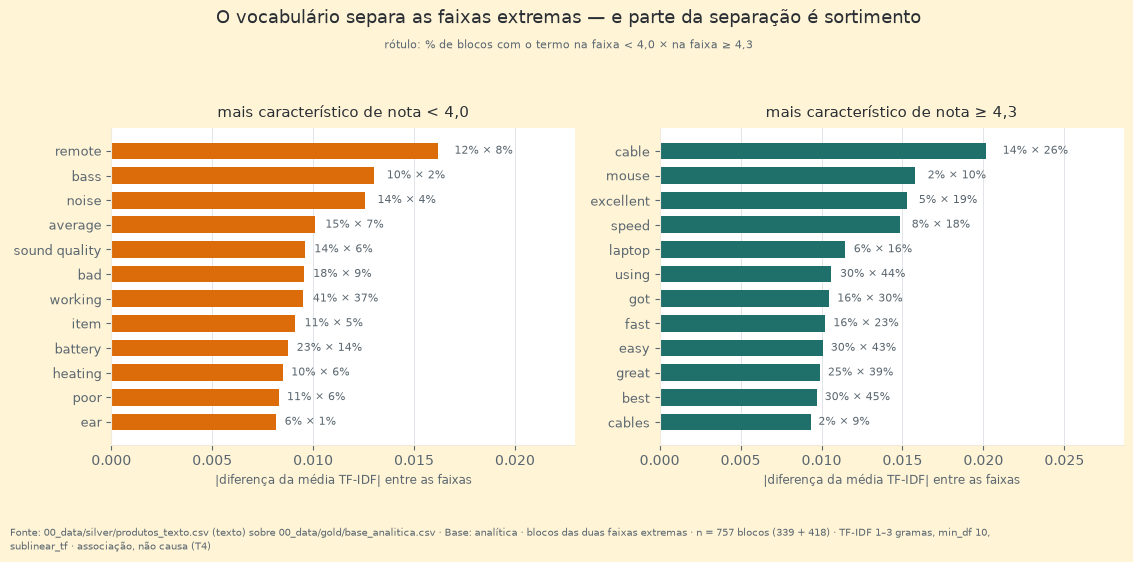

gravado: 02_results/images/fig_nlp_02_contraste_ngramas.png


In [11]:
TOPO_FIG = 12
esq = contraste[contraste.faixa_nota == "< 4,0"].nlargest(TOPO_FIG, "delta_tfidf").iloc[::-1]
dir_ = contraste[contraste.faixa_nota == "≥ 4,3"].nsmallest(TOPO_FIG, "delta_tfidf").iloc[::-1]
checar_series(2)

fig, eixos = plt.subplots(1, 2, figsize=(11.4, 5.6), sharex=False)

for ax, dados, cor, titulo, sinal in [
    (eixos[0], esq, CHAMADAS["atencao"], "mais característico de nota < 4,0", 1),
    (eixos[1], dir_, CHAMADAS["favoravel"], "mais característico de nota ≥ 4,3", -1),
]:
    y = np.arange(len(dados))
    valores = dados.delta_tfidf.abs().values
    ax.barh(y, valores, color=cor, height=0.68)
    ax.set_yticks(y)
    ax.set_yticklabels(dados.n_grama.values, fontsize=9)
    ax.set_title(titulo, fontsize=10.5, color=ESTRUTURA["tinta"], pad=8)
    ax.set_xlabel("|diferença da média TF-IDF| entre as faixas", fontsize=8.5)
    ax.set_xlim(0, valores.max() * 1.42)
    ax.grid(axis="y", visible=False)
    for i, (v, sb, sa) in enumerate(zip(valores, dados.share_blocos_baixa_pct, dados.share_blocos_alta_pct)):
        ax.text(v * 1.05, i, f"{sb:.0f}% × {sa:.0f}%", va="center", fontsize=7.8,
                color=ESTRUTURA["secundario"])

fig.suptitle("O vocabulário separa as faixas extremas — e parte da separação é sortimento",
             fontsize=13, color=ESTRUTURA["tinta"], y=0.975)
fig.text(0.5, 0.905, "rótulo: % de blocos com o termo na faixa < 4,0 × na faixa ≥ 4,3",
         ha="center", fontsize=8.2, color=ESTRUTURA["secundario"])
rodape(fig, "00_data/silver/produtos_texto.csv (texto) sobre 00_data/gold/base_analitica.csv",
       "analítica · blocos das duas faixas extremas", "757 blocos (339 + 418)",
       "TF-IDF 1–3 gramas, min_df 10, sublinear_tf · associação, não causa (T4)")
fig.tight_layout(rect=[0, 0.095, 1, 0.89])
destino = os.path.join(IMG, "fig_nlp_02_contraste_ngramas.png")
confere_visual(fig, "figura")          # T3 e T9 conferidos na figura
fig.savefig(destino, dpi=160)
plt.show()
print("gravado:", os.path.relpath(destino, RAIZ))

### 6.2 Exportação — `tab14_ngramas.csv`

Uma tabela só, com duas seções identificadas pela coluna `secao`:

- `frequencia` — os n-gramas mais frequentes **por faixa de nota** (as três faixas, inclusive a
  intermediária);
- `contraste` — o contraste TF-IDF entre as faixas extremas, no recorte geral **e** no recorte de
  controle Electronics.

Toda linha carrega `base`, `n_blocos_faixa` e o critério — T3 vale para tabela, não só para figura.

In [12]:
frequencia_out = frequencia.assign(
    secao="frequencia",
    recorte="base analítica",
    share_blocos_baixa_pct=np.nan,
    share_blocos_alta_pct=np.nan,
    tfidf_medio_baixa=np.nan,
    tfidf_medio_alta=np.nan,
    delta_tfidf=np.nan,
    criterio="frequência documental (blocos com o termo), min_df=5",
)

blocos_por_faixa = base.faixa_nota.value_counts()
contraste_out = pd.concat([contraste, contraste_el], ignore_index=True).assign(
    secao="contraste",
    criterio="diferença da média TF-IDF (1–3 gramas, min_df=10, sublinear_tf=True)",
)
contraste_out["blocos_com_o_termo"] = np.nan
contraste_out["n_blocos_faixa"] = np.where(
    contraste_out.recorte == "Electronics",
    np.where(contraste_out.faixa_nota == "< 4,0", info_el["baixa"], info_el["alta"]),
    np.where(contraste_out.faixa_nota == "< 4,0", info_geral["baixa"], info_geral["alta"]),
)
contraste_out["share_blocos_pct"] = np.where(
    contraste_out.faixa_nota == "< 4,0",
    contraste_out.share_blocos_baixa_pct, contraste_out.share_blocos_alta_pct)

COLUNAS = ["secao", "recorte", "faixa_nota", "n_blocos_faixa", "grau", "n_grama",
           "blocos_com_o_termo", "share_blocos_pct", "share_blocos_baixa_pct",
           "share_blocos_alta_pct", "tfidf_medio_baixa", "tfidf_medio_alta",
           "delta_tfidf", "criterio"]
tab11 = pd.concat([frequencia_out[COLUNAS], contraste_out[COLUNAS]], ignore_index=True)
tab11["unidade"] = "bloco de review (até 8 avaliações por produto — L1)"
tab11["base"] = "00_data/gold/base_analitica.csv + texto de 00_data/silver/produtos_texto.csv"
tab11["n_blocos_total"] = len(base)

destino_tab = os.path.join(TAB, "tab14_ngramas.csv")
tab11.to_csv(destino_tab, index=False, encoding="utf-8")
print("gravado:", os.path.relpath(destino_tab, RAIZ), "·", f"{len(tab11)} linhas")
print(tab11.groupby(["secao", "recorte", "faixa_nota"], dropna=False).size().to_string())
print()
print(tab11.head(6).to_string(index=False))

gravado: 02_results/tables/tab14_ngramas.csv · 105 linhas
secao       recorte         faixa_nota
contraste   Electronics     < 4,0         15
                            ≥ 4,3         15
            base analítica  < 4,0         15
                            ≥ 4,3         15
frequencia  base analítica  4,0–4,29      15
                            < 4,0         15
                            ≥ 4,3         15

     secao        recorte faixa_nota  n_blocos_faixa  grau n_grama  blocos_com_o_termo  share_blocos_pct  share_blocos_baixa_pct  share_blocos_alta_pct  tfidf_medio_baixa  tfidf_medio_alta  delta_tfidf                                             criterio                                             unidade                                                                         base  n_blocos_total
frequencia base analítica      < 4,0             339     1    good               314.0              92.6                     NaN                    NaN                NaN               Na

## 7. QA5 · leitura qualitativa dirigida — **TF-IDF vedado aqui**

> *Quais temas de reclamação predominam nos produtos de alto engajamento e baixa nota?*

O corpus são **19 blocos** — os produtos do quadrante Q5 (`rating_count` ≥ 36.384 **e** nota < 4,0),
com **147 referências de avaliação** e cerca de 49,5 mil caracteres.

### Por que TF-IDF está vedado neste corpus

Com 19 documentos, o IDF de um termo passa a ser função de aparecer em 1, 2 ou 3 blocos. A diferença
entre "termo raro" e "termo comum" vira um degrau de um produto. O método continuaria rodando e
devolvendo uma tabela com quatro casas decimais — **e é exatamente por isso que é perigoso**: a
saída parece medida quando é ruído. A vedação está em `escopo_perguntas.md`, seção 4.

### O que entra no lugar: protocolo de codificação declarado

Leitura qualitativa **dirigida**, com livro de códigos registrado **antes** da contagem e aplicado
de forma determinística, para que qualquer pessoa reexecute e chegue ao mesmo resultado.

| Item do protocolo | Definição |
|---|---|
| **Unidade de registro** | o **bloco** (= o produto). n = 19. Nunca a opinião individual |
| **Livro de códigos** | 9 eixos temáticos, cada um com lista fechada de termos de inclusão, fixada na célula abaixo |
| **Passo 1 — presença** | o eixo é marcado quando **ao menos um** termo de inclusão ocorre no bloco |
| **Passo 2 — valência** | o eixo recebe **marcador negativo** quando um termo de inclusão ocorre a até **60 caracteres** de um marcador de insatisfação (`not`, `poor`, `problem`, `stopped`, `waste`, …) |
| **Multiplicidade** | um bloco pode receber vários eixos; os eixos **não** são mutuamente exclusivos |
| **Contagem** | presença/ausência **por bloco**, nunca por avaliação — e nunca convertida em proporção de clientes |
| **Texto bruto** | **não é impresso** em nenhuma saída: o conteúdo das avaliações contém nomes de consumidores, e T7 veda identificador pessoal em qualquer saída |

### O que este protocolo **não** é

Não é estimativa da frequência de reclamações. É um **inventário do que está visível na vitrine
destes 19 produtos** (L1). Dizer "X% dos clientes reclamam de bateria" seria inventar um
denominador que a base não tem.

**Nota sobre T2:** o piso de 30 não se aplica — `escopo_perguntas.md` e T2 registram que listas
nominais de produtos (Q5, Q6, QA5) não são grupos agregados. Ainda assim, nenhum eixo é **ranqueado
contra outro** abaixo: a tabela mostra contagem sobre o denominador de 19, sempre visível.

**Nota sobre D-5:** confrontar os atributos anunciados em `about_product` com o que as avaliações
dizem nestes 19 produtos ficou **fora do escopo**. A decisão fechou em 01/10/2026: `about_product`
descreve a promessa do vendedor, não a percepção do consumidor, e Customer Insights mede percepção.

In [13]:
#: Livro de códigos — fixado ANTES da contagem. Alterar aqui exige reexecutar e republicar.
LIVRO_DE_CODIGOS = {
    "Bateria e autonomia": ["battery", "batteries", "charge", "charging", "charged",
                            "backup", "mah", "playback", "drain"],
    "Falha e durabilidade": ["stopped working", "not working", "stop working", "broke", "broken",
                             "damaged", "dead", "died", "defect", "faulty", "warranty",
                             "replace", "replacement", "repair", "fault"],
    "Som, ruído e microfone": ["sound", "bass", "mic", "noise", "treble", "volume",
                               "latency", "audio", "loud", "noisy"],
    "Conforto e encaixe": ["fit", "fitting", "comfortable", "uncomfortable", "tight", "loose",
                           "slipping", "hurt", "cushion", "pain", "ear tip", "headband"],
    "Construção e acabamento": ["build quality", "plastic", "flimsy", "scratch", "material",
                                "finishing", "wire", "cord"],
    "Entrega, embalagem e pós-venda": ["packaging", "packing", "delivery", "delivered",
                                       "return", "seller", "service", "missing"],
    "Expectativa versus descrição": ["misleading", "claim", "description", "advertised",
                                     "deceiv", "fraud", "expected", "fake", "genuine"],
    "Desempenho na tarefa": ["slow", "time consuming", "heating", "not effective", "weak",
                             "accuracy", "accurate", "performance", "efficient", "speed"],
    "Preço e custo-benefício": ["price", "worth", "money", "value", "budget", "cost"],
}

#: Marcadores de insatisfação — passo 2 do protocolo.
MARCADORES_NEGATIVOS = ["not ", "n't", "no ", "never", "poor", "bad", "worst", "worse", "issue",
                        "problem", "fail", "stopped", "stop ", "waste", "useless", "disappoint",
                        "cheap", "weak", "low ", "less", "lack", "unable", "hardly", "barely",
                        "damag", "defect", "return", "complain", "sucks", "average", "only "]

JANELA = 60  # caracteres de cada lado do termo de inclusão


def codificar(bloco):
    """Aplica os dois passos do protocolo a um bloco. Devolve (presença, valência negativa)."""
    texto = str(bloco).lower()
    presenca, negativo = {}, {}
    for eixo, termos in LIVRO_DE_CODIGOS.items():
        tem, neg = False, False
        for termo in termos:
            for achado in re.finditer(re.escape(termo), texto):
                tem = True
                janela = texto[max(0, achado.start() - JANELA): achado.end() + JANELA]
                if any(m in janela for m in MARCADORES_NEGATIVOS):
                    neg = True
                    break
            if neg:
                break
        presenca[eixo], negativo[eixo] = tem, neg
    return presenca, negativo


q5 = base[base.q5_risco_vitrine].copy()
print(f"Blocos no quadrante Q5 (engajamento ≥ p90 = 36.384 e nota < 4,0): {len(q5)}")
print(f"Referências de avaliação nestes blocos : {int(q5.refs_no_bloco.sum())}")
print(f"Caracteres de texto bruto              : {int(q5.review_content.str.len().sum()):,}".replace(",", "."))
conferir("blocos do quadrante Q5", len(q5), 19)
conferir("referências nos blocos de Q5", int(q5.refs_no_bloco.sum()), 147)

codificado = q5.review_content.fillna("").apply(codificar)
presenca = pd.DataFrame([c[0] for c in codificado], index=q5.index)
negativo = pd.DataFrame([c[1] for c in codificado], index=q5.index)

qa5 = pd.DataFrame({
    "blocos_com_o_eixo": presenca.sum(),
    "blocos_com_marcador_negativo": negativo.sum(),
})
qa5["de_um_total_de"] = len(q5)
qa5["share_negativo_pct"] = (qa5.blocos_com_marcador_negativo / len(q5) * 100).round(1)
qa5 = qa5.sort_values("blocos_com_marcador_negativo", ascending=False)

print("\nQA5 — EIXOS TEMÁTICOS CODIFICADOS (unidade: bloco · denominador sempre visível)")
print(qa5.to_string())
print()
print(f"Blocos sem nenhum eixo com marcador negativo : {int((negativo.sum(axis=1) == 0).sum())} de {len(q5)}")
print(f"Média de eixos negativos por bloco           : {negativo.sum(axis=1).mean():.2f}")

Blocos no quadrante Q5 (engajamento ≥ p90 = 36.384 e nota < 4,0): 19
Referências de avaliação nestes blocos : 147
Caracteres de texto bruto              : 49.516

QA5 — EIXOS TEMÁTICOS CODIFICADOS (unidade: bloco · denominador sempre visível)
                                blocos_com_o_eixo  blocos_com_marcador_negativo  de_um_total_de  share_negativo_pct
Som, ruído e microfone                         15                            15              19                78.9
Preço e custo-benefício                        18                            14              19                73.7
Bateria e autonomia                            11                            10              19                52.6
Conforto e encaixe                             11                             9              19                47.4
Desempenho na tarefa                           13                             9              19                47.4
Construção e acabamento                         9            

In [14]:
# Composição do quadrante — sem ela, o inventário temático é lido como se fosse do portfólio.
q5 = q5.assign(familia=np.where(
    q5.categoria_n2.str.contains("Headphones|HomeAudio", regex=True), "áudio pessoal",
    np.where(q5.categoria_n1 == "Home&Kitchen", "eletrodoméstico de cozinha", "outros")))

print("COMPOSIÇÃO DOS 19 BLOCOS DE Q5")
print(q5.familia.value_counts().to_string())
print()
print(q5.categoria_n2.value_counts().to_string())
print()
print("Leitura obrigatória: 11 dos 19 blocos são de áudio pessoal. O eixo 'Som, ruído e microfone'")
print("aparece no topo em parte porque o quadrante É majoritariamente fone de ouvido. O eixo")
print("descreve ESTES 19 produtos, e não se estende ao portfólio.")
print()

# Lista nominal — exceção declarada de T2. Sem user_id e sem user_name (T7).
nominal = q5[["product_id", "product_name", "categoria_n2", "nota", "nota_corrigida",
              "avaliacoes", "refs_no_bloco"]].sort_values("avaliacoes", ascending=False)
nominal = nominal.assign(product_name=nominal.product_name.str.slice(0, 58) + "…")
print("OS 19 PRODUTOS — lista nominal, com o n de avaliações ao lado (T1, T2, T7)")
print(nominal.to_string(index=False))

COMPOSIÇÃO DOS 19 BLOCOS DE Q5
familia
áudio pessoal                 11
eletrodoméstico de cozinha     6
outros                         2

categoria_n2
Electronics | Headphones,Earbuds&Accessories    10
Home&Kitchen | Kitchen&HomeAppliances            6
Electronics | HomeAudio                          1
Electronics | Mobiles&Accessories                1
Electronics | Cameras&Photography                1

Leitura obrigatória: 11 dos 19 blocos são de áudio pessoal. O eixo 'Som, ruído e microfone'
aparece no topo em parte porque o quadrante É majoritariamente fone de ouvido. O eixo
descreve ESTES 19 produtos, e não se estende ao portfólio.

OS 19 PRODUTOS — lista nominal, com o n de avaliações ao lado (T1, T2, T7)
product_id                                                product_name                                 categoria_n2  nota  nota_corrigida  avaliacoes  refs_no_bloco
B08JQN8DGZ boAt Airdopes 121v2 in-Ear True Wireless Earbuds with Upto… Electronics | Headphones,Earbuds&Accessorie

### 7.1 Figura 3 — os eixos codificados

Duas séries (T9): a barra clara é a **presença** do eixo no bloco; a barra escura, a presença
**com marcador negativo de valência** a até 60 caracteres. A distância entre as duas é informação:
onde as barras quase coincidem, o eixo aparece quase sempre em contexto de insatisfação; onde se
afastam, o tema é discutido nos dois sentidos dentro do mesmo bloco — o que é esperado num bloco
que reúne até 8 avaliações de opiniões diferentes.

O denominador (19) está no eixo e no rodapé, porque uma barra de 15 sobre 19 lida sem denominador
vira "a maioria" — e L1 proíbe essa leitura.

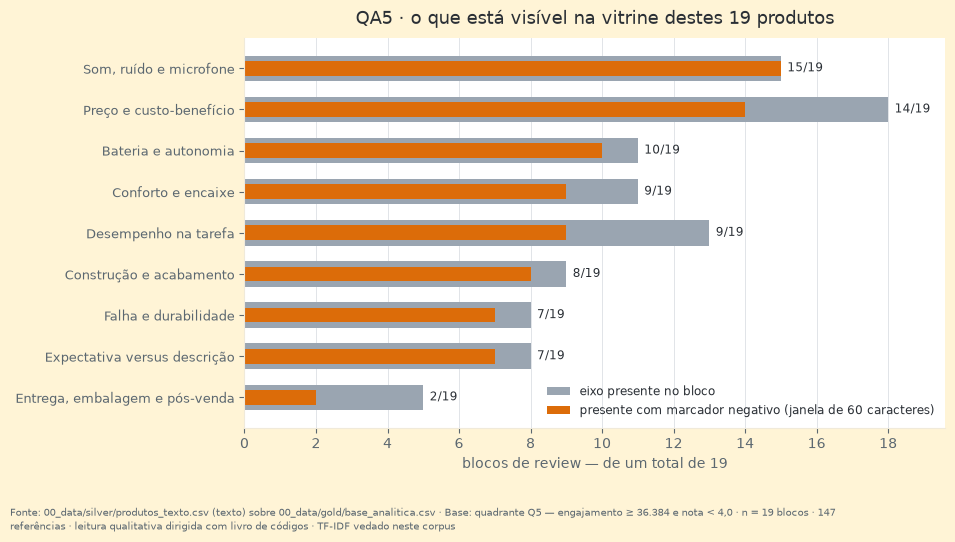

gravado: 02_results/images/fig_nlp_03_qa5_eixos_tematicos.png


In [15]:
dados = qa5.iloc[::-1]
y = np.arange(len(dados))
checar_series(2)

fig, ax = plt.subplots(figsize=(9.6, 5.4))
ax.barh(y, dados.blocos_com_o_eixo, color=ESTRUTURA["grade"], height=0.62,
        label="eixo presente no bloco")
ax.barh(y, dados.blocos_com_marcador_negativo, color=CHAMADAS["atencao"], height=0.36,
        label="presente com marcador negativo (janela de 60 caracteres)")
ax.set_yticks(y)
ax.set_yticklabels(dados.index, fontsize=9.5)
ax.set_xlim(0, len(q5) + 0.6)
ax.set_xticks(range(0, len(q5) + 1, 2))
ax.set_xlabel(f"blocos de review — de um total de {len(q5)}")
ax.grid(axis="y", visible=False)
for i, (p, n) in enumerate(zip(dados.blocos_com_o_eixo, dados.blocos_com_marcador_negativo)):
    ax.text(p + 0.18, i, f"{n}/{len(q5)}", va="center", fontsize=8.5, color=ESTRUTURA["tinta"])
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("QA5 · o que está visível na vitrine destes 19 produtos", pad=10)

rodape(fig, "00_data/silver/produtos_texto.csv (texto) sobre 00_data/gold/base_analitica.csv",
       "quadrante Q5 — engajamento ≥ 36.384 e nota < 4,0",
       "19 blocos · 147 referências",
       "leitura qualitativa dirigida com livro de códigos · TF-IDF vedado neste corpus")
fig.tight_layout(rect=[0, 0.09, 1, 1])
destino = os.path.join(IMG, "fig_nlp_03_qa5_eixos_tematicos.png")
confere_visual(fig, "figura")          # T3 e T9 conferidos na figura
fig.savefig(destino, dpi=160)
plt.show()
print("gravado:", os.path.relpath(destino, RAIZ))

### 7.2 Exportação — `tab23_qa5_temas.csv`

O dashboard não reexecuta a codificação: o Power Query refaz a preparação, mas o livro de códigos
vive aqui. A página 4 importa esta tabela, sem relação com o modelo — ela descreve os 19 blocos de
Q5 e não responde a filtro.

Uma linha por eixo, com o **denominador em toda linha** (T3) e o critério declarado. **Nenhum texto de
avaliação e nenhum identificador** — só contagens por bloco (T7). A tabela é a mesma que alimenta
a Figura 3, então as duas não podem divergir.

In [16]:
tab23 = (qa5.rename_axis("eixo_tematico").reset_index()
         .assign(unidade="bloco de review (= produto) · até 8 avaliações por bloco — L1",
                 criterio=f"livro de códigos fixo · marcador negativo a até {JANELA} caracteres do termo",
                 base="quadrante Q5 de 00_data/gold/base_analitica.csv + texto de 00_data/silver/produtos_texto.csv"))

destino_tab23 = os.path.join(TAB, "tab23_qa5_temas.csv")
tab23.to_csv(destino_tab23, index=False, encoding="utf-8")
print("gravado:", os.path.relpath(destino_tab23, RAIZ), "·", f"{len(tab23)} linhas")
print(tab23[["eixo_tematico", "blocos_com_o_eixo", "blocos_com_marcador_negativo",
             "de_um_total_de", "share_negativo_pct"]].to_string(index=False))

conferir("tab23 · um eixo por linha do livro de códigos", len(tab23), len(LIVRO_DE_CODIGOS))
conferir("tab23 · denominador = blocos de Q5", int(tab23.de_um_total_de.unique()[0]), 19)
conferir("tab23 · nenhuma coluna de texto ou de usuário",
         any(c in tab23.columns for c in ["review_content", "user_id", "user_name", "review_id"]), False)

gravado: 02_results/tables/tab23_qa5_temas.csv · 9 linhas
                 eixo_tematico  blocos_com_o_eixo  blocos_com_marcador_negativo  de_um_total_de  share_negativo_pct
        Som, ruído e microfone                 15                            15              19                78.9
       Preço e custo-benefício                 18                            14              19                73.7
           Bateria e autonomia                 11                            10              19                52.6
            Conforto e encaixe                 11                             9              19                47.4
          Desempenho na tarefa                 13                             9              19                47.4
       Construção e acabamento                  9                             8              19                42.1
          Falha e durabilidade                  8                             7              19                36.8
  Expectativa 

True

## 8. Leitura — o que este notebook sustenta, e com que força

Redigido sob **T4** (nenhuma frase afirma causa), **T5** (magnitude junto de significância),
**T6** (`rating_count` é volume de avaliações) e **L1** (nenhuma frase começa por *"a maioria dos
clientes"*, porque o corpus não autoriza).

**Contraste de vocabulário entre as faixas (tab14)**

1. **O vocabulário comum satura e não separa nada.** `good` e `product` estão em 88% ou mais dos blocos de
   **todas** as faixas, e `quality` e `price` em 46% a 68%. Publicar a frequência bruta como achado seria
   publicar a saturação. O sinal está no contraste, e só nele.
2. **Onde há contraste, ele é de magnitude pequena.** A maior diferença de média TF-IDF entre as
   faixas extremas fica na casa de 0,02 — associação, não separação. Um classificador de faixa de
   nota construído só sobre este vocabulário não é sustentado por esta medida, e o projeto não propõe um.
3. **Parte do contraste é mix de sortimento, e isso é verificável.** Termos que somem quando o
   recorte se fecha em Electronics eram vocabulário de categoria, não de satisfação. Os que
   sobrevivem aos dois recortes — e a lista está impressa na seção 6 — são os únicos candidatos a
   padrão temático.
4. **A faixa intermediária ficou fora.** São 591 produtos, 44% do portfólio. É escolha de método
   registrada no projeto, não esquecimento, e é dita aqui porque quem lê só o contraste imagina um
   portfólio polarizado que não existe.

**QA5 — temas nos 19 produtos de alto engajamento e nota baixa**

5. **O inventário descreve 19 produtos, não o portfólio.** Dos 19, **11 são de áudio pessoal** e
   **6 são eletrodoméstico de cozinha**. O eixo mais codificado está associado à composição do
   quadrante tanto quanto ao conteúdo das avaliações — e isso está impresso ao lado do resultado.
6. **Eixos técnicos e de durabilidade aparecem com marcador negativo em parte relevante dos 19
   blocos.** A contagem está na tabela, sempre sobre o denominador 19. A leitura útil para o negócio
   é *onde olhar primeiro na revisão destes itens*, não *quanto do público pensa assim*.
7. **Um eixo presente em quase todos os blocos não discrimina.** "Preço e custo-benefício" aparece
   em 18 dos 19. Isso diz que preço é assunto onipresente na avaliação de e-commerce indiano deste
   recorte — não que preço distinga os produtos problemáticos.

**O que nenhum número deste notebook autoriza dizer**

- Que um tema **causa** nota baixa — T4. As medidas são associações entre vocabulário e faixa.
- Que os temas representam **a opinião dos clientes** — L1. São os temas **visíveis na vitrine**,
  no recorte de até 8 avaliações que o marketplace escolheu exibir.
- Que alto volume de avaliações significa **venda, receita ou demanda** — T6. É volume de avaliações.
- Qualquer proporção de consumidores. Não há denominador de clientes nesta base — só de blocos.

## 9. Célula final de validação

Reconciliação contra `method/definitions/base_factual_e_bases_de_calculo.md`,
`method/definitions/registro_machine_learning.md` e `02_results/tables/tab06_corpus.csv`.

Se qualquer linha sair como **DIVERGE**, o notebook falha — não imprime aviso e segue. Um número
que não reconcilia com o material é um número que não pode ser publicado.

In [17]:
# Conferências finais que dependem das saídas gravadas.
for nome in ["fig_nlp_01_truncamento_corpus.png", "fig_nlp_02_contraste_ngramas.png",
             "fig_nlp_03_qa5_eixos_tematicos.png"]:
    conferir(f"figura gravada · {nome}", os.path.exists(os.path.join(IMG, nome)), True)
conferir("tabela gravada · tab14_ngramas.csv", os.path.exists(os.path.join(TAB, "tab14_ngramas.csv")), True)
conferir("tabela gravada · tab23_qa5_temas.csv", os.path.exists(os.path.join(TAB, "tab23_qa5_temas.csv")), True)

# As figuras fig01 a fig13 não podem ter sido tocadas por este notebook. A conferência
# testa a PRESENÇA das treze, e não a contagem de arquivos: os demais notebooks do
# projeto escrevem no mesmo diretório, com prefixo fig_<notebook>_.
existentes = set(os.listdir(IMG))
faltando_antigas = [f for f in sorted(existentes) if re.match(r"fig(0[1-9]|1[0-3])_", f)]
conferir("figuras fig01–fig13 preservadas", len(faltando_antigas), 13)
conferir("nenhuma figura antiga sobrescrita por este notebook",
         all(not f.startswith("fig_nlp_") for f in faltando_antigas), True)

# Contraste com a tabela de corpus já publicada pelo notebook 04.
caminho_tab06 = os.path.join(TAB, "tab06_corpus.csv")
if os.path.exists(caminho_tab06):
    tab06 = pd.read_csv(caminho_tab06)
    medido = corpus.loc[ORDEM_FAIXA, ["blocos", "referencias", "reviews_distintos"]].reset_index(drop=True)
    publicado = tab06.set_index("faixa_nota").reindex(ORDEM_FAIXA)[
        ["blocos", "referencias", "reviews_distintos"]].reset_index(drop=True)
    conferir("corpus bate com tab06_corpus.csv", bool(medido.equals(publicado)), True)
else:
    print("AVISO: tab06_corpus.csv ausente — conferência cruzada não executada.")

relatorio = pd.DataFrame(VALIDACAO)
print("VALIDAÇÃO FINAL — 05_nlp.ipynb")
print(relatorio.to_string(index=False))

divergencias = relatorio[relatorio["situação"] == "DIVERGE"]
if len(divergencias):
    raise AssertionError(f"{len(divergencias)} conferência(s) divergem do material:\n{divergencias}")

print()
print(f"{len(relatorio)} conferências · todas confer" + "em com o material do projeto.")
print()
print("RESUMO DO CORPUS (T8) — unidade declarada: bloco de review")
print(f"  blocos              : {len(base):,}".replace(",", "."))
print(f"  referências         : {len(refs):,}".replace(",", ".") + "  (1.333 repetidas)")
print(f"  reviews distintos   : {distintos._rid.nunique():,}".replace(",", ".") + "  (deduplicado por review_id)")
print("  truncamento         : média " + f"{base.refs_no_bloco.mean():.2f}".replace(".", ",")
      + f" · máximo {base.refs_no_bloco.max()} (L1)")
print()
print("SAÍDAS")
for arquivo in ["02_results/images/fig_nlp_01_truncamento_corpus.png",
                "02_results/images/fig_nlp_02_contraste_ngramas.png",
                "02_results/images/fig_nlp_03_qa5_eixos_tematicos.png",
                "02_results/tables/tab14_ngramas.csv",
                "02_results/tables/tab23_qa5_temas.csv"]:
    print(f"  {arquivo}")

VALIDAÇÃO FINAL — 05_nlp.ipynb


                                        verificação obtido esperado situação
                            blocos (base analítica)   1348     1348  confere
                           referências de avaliação  10588    10588  confere
                                  reviews distintos   9255     9255  confere
                              referências repetidas   1333     1333  confere
                                 truncamento máximo      8        8  confere
                                  blocos nota < 4,0    339      339  confere
                                  blocos nota ≥ 4,3    418      418  confere
                       reviews distintos nota < 4,0   2502     2502  confere
                       reviews distintos nota ≥ 4,3   2878     2878  confere
                                    bronze — linhas   1465     1465  confere
                                  silver — produtos   1351     1351  confere
                    blocos no contraste (339 + 418)    757      757  confer